In [148]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

Data preparation

In [104]:
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')

In [105]:
df

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
...,...,...,...,...,...,...,...,...,...
4995,organic_search,education,employed,asia,45834.0,2,2,0.37,1
4996,NaN,technology,employed,north_america,84831.0,2,5,0.51,0
4997,organic_search,finance,employed,asia,53636.0,4,6,0.75,1
4998,referral,technology,employed,africa,69430.0,4,8,0.79,1


In [106]:
df.shape

(5000, 9)

In [107]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [108]:
categorical = list(df.dtypes[df.dtypes == 'str'].index)
df.columns = df.columns.str.lower().str.replace(" ", "_")

In [109]:
for c in categorical:
    df[c] = df[c].str.lower().str.replace(" ", "_")

In [110]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [111]:
df.columns

Index(['lead_source', 'industry', 'employment_status', 'location',
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score', 'converted'],
      dtype='str')

In [112]:
categorical

['lead_source', 'industry', 'employment_status', 'location']

In [113]:
numerical =['annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score']

In [114]:
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

In [115]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

In [116]:
del df_train['converted']
del df_val['converted']
del df_test['converted']

In [117]:
df.isnull()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...
4995,False,False,False,False,False,False,False,False,False
4996,False,False,False,False,False,False,False,False,False
4997,False,False,False,False,False,False,False,False,False
4998,False,False,False,False,False,False,False,False,False


In [118]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

 Question 1 : ROC AUC feature importance

In [119]:
for c in numerical:
    auc = roc_auc_score(y_train, df_train[c])
    if auc < 0.5:
       auc = roc_auc_score(y_train, -df_train[c])
    print(c, auc)

annual_income 0.6081977776250831
number_of_courses_viewed 0.7229894623989618
interaction_count 0.7649203047563227
lead_score 0.7882254810906102


Question 2 : Training the model

In [120]:

features = categorical + numerical

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train[features].to_dict(orient='records'))
X_val = dv.transform(df_val[features].to_dict(orient='records'))

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)


,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [121]:
y_pred = model.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred)
round(auc,3)

0.732

Question 3 : Precision and Recall

In [122]:
scores = []

thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    scores.append((t, tp, fp, fn, tn))

In [123]:
columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)

In [124]:
df_scores['precision'] = (df_scores.tp / (df_scores.tp + df_scores.fp))
df_scores['recall'] = ( df_scores.tp / (df_scores.tp + df_scores.fn))

Text(0.5, 1.0, 'Precision and Recall vs threshold')

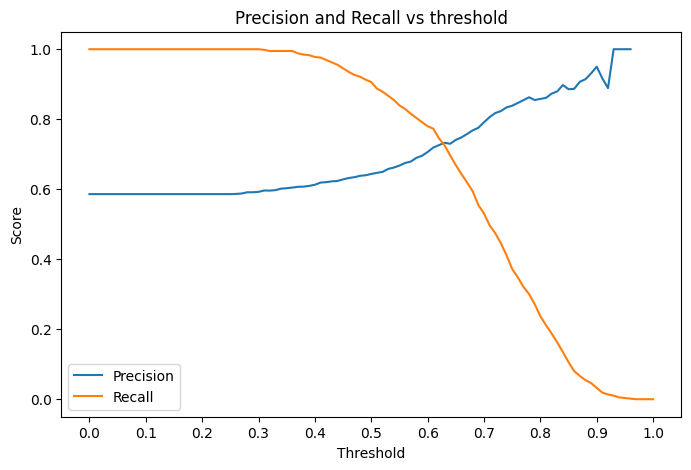

In [125]:
plt.figure(figsize=(8, 5))
plt.plot(df_scores.threshold, df_scores.precision, label='Precision')
plt.plot(df_scores.threshold, df_scores.recall, label='Recall')
plt.xticks(np.arange(0, 1.01, 0.1))
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.title('Precision and Recall vs threshold')

In [126]:
df_scores['difference'] = abs( df_scores.precision - df_scores.recall)

d = df_scores[
    (df_scores.precision > 0) |
    (df_scores.recall > 0)
]

d.iloc[d.difference.idxmin()]

threshold       0.630000
tp            425.000000
fp            155.000000
fn            161.000000
tn            259.000000
precision       0.732759
recall          0.725256
difference      0.007503
Name: 63, dtype: float64

In [127]:
df_scores

,threshold,tp,fp,fn,tn,precision,recall,difference
0,0.00,586,414,0,0,0.586,1.000000,0.414000
1,0.01,586,414,0,0,0.586,1.000000,0.414000
2,0.02,586,414,0,0,0.586,1.000000,0.414000
3,0.03,586,414,0,0,0.586,1.000000,0.414000
4,0.04,586,414,0,0,0.586,1.000000,0.414000
...,...,...,...,...,...,...,...,...
96,0.96,1,0,585,414,1.000,0.001706,0.998294
97,0.97,0,0,586,414,NaN,0.000000,NaN
98,0.98,0,0,586,414,NaN,0.000000,NaN
99,0.99,0,0,586,414,NaN,0.000000,NaN


Question 4 : F1 score

In [128]:
df_scores['f1'] = (2 * df_scores.precision * df_scores.recall / (df_scores.precision + df_scores.recall))
df_scores = df_scores.fillna(0)

df_scores.iloc[df_scores.f1.idxmax()]

threshold       0.410000
tp            572.000000
fp            352.000000
fn             14.000000
tn             62.000000
precision       0.619048
recall          0.976109
difference      0.357062
f1              0.757616
Name: 41, dtype: float64

Question 5 : 5-Fold CV

In [129]:
def train(df_tr, y_tr, C=1.0):
    dv = DictVectorizer(sparse=False)
    X_tr = dv.fit_transform(df_tr[features].to_dict(orient='records'))
    m = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    m.fit(X_tr, y_tr)
    return dv, m


def predict(df_x, dv, m):
    X = dv.transform(df_x[features].to_dict(orient='records'))
    return m.predict_proba(X)[:, 1]

In [130]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

In [131]:
scores = []
for train_idx, val_idx in kfold.split(df_full_train):
    df_tr = df_full_train.iloc[train_idx]
    df_va = df_full_train.iloc[val_idx]

    dv, m = train(df_tr, df_tr.converted.values)
    scores.append(roc_auc_score(df_va.converted.values, predict(df_va, dv, m)))

In [132]:
for s in scores :
    e = round(s, 4)

    print([e])

[0.7306]
[0.7296]
[0.7363]
[0.7412]
[0.7209]


In [133]:
np.mean(scores)

np.float64(0.7317269710972524)

In [134]:
np.std(scores)

np.float64(0.006853233151022138)

In [135]:
round(np.std(scores), 3)

np.float64(0.007)

Question 6 : Hyperparameter Tuning

In [156]:
for C in [0.000001, 0.001, 1]:
    scores = []
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        train_dicts = df_train.drop(columns='converted').to_dict(orient='records')
        val_dicts = df_val.drop(columns='converted').to_dict(orient='records')

        dv = DictVectorizer(sparse=False)
        X_train = dv.fit_transform(train_dicts)
        X_val = dv.transform(val_dicts)

        model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        model.fit(X_train, y_train)

        y_pred = model.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        
        scores.append(auc)  # Added this to store fold results
    
    
    
    print(f'C={C:<10} mean={round(np.mean(scores), 3)}  std={round(np.std(scores), 3)}')

C=1e-06      mean=0.617  std=0.019
C=0.001      mean=0.749  std=0.01
C=1          mean=0.732  std=0.007
